# AIAP Module 7 Capstone Project: Exploratory Data Analysis

**Goal:** understand the diabetes early-detection dataset before modelling.

This notebook covers the first stage of EDA:

1. Setup
2. Load & first look
3. Data quality checks (empty rows, missing values, duplicates, invalid categories, implausible values)
4. Univariate analysis of numeric features (distributions, normality)
5. Outlier analysis (IQR and z-score)
6. Univariate analysis of categorical features and the target
7. Summary of findings

Bivariate analysis (features vs `diabetes_diagnosis`) comes in the next stage.

## 1. Setup

In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

DATA_PATH = Path("data/synthetic_data_166.csv")
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

## 2. Load & first look

We check the shape, the first rows and the data types. Each column should have the type we expect: numbers for the measurements and text for the categories.

In [21]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1000, 8)


,age,bmi,blood_pressure,fasting_glucose_level,cholesterol_level,physical_activity_frequency,family_history_of_diabetes,diabetes_diagnosis
0,64,25.13,120.88,111.90,128.59,0.355,Absent,Negative
1,67,35.13,133.56,116.20,141.34,0.092,Present,Negative
2,69,31.09,128.18,112.08,220.89,0.275,Present,Negative
3,62,30.24,136.50,128.53,215.73,0.101,Present,Negative
4,28,28.75,138.66,116.37,227.55,0.262,Absent,Negative


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          1000 non-null   int64  
 1   bmi                          1000 non-null   float64
 2   blood_pressure               1000 non-null   float64
 3   fasting_glucose_level        1000 non-null   float64
 4   cholesterol_level            1000 non-null   float64
 5   physical_activity_frequency  1000 non-null   float64
 6   family_history_of_diabetes   1000 non-null   object 
 7   diabetes_diagnosis           1000 non-null   object 
dtypes: float64(5), int64(1), object(2)
memory usage: 62.6+ KB


In [23]:
TARGET = "diabetes_diagnosis"
NUM_COLS = df.select_dtypes(include="number").columns.tolist()
CAT_COLS = [c for c in df.columns if c not in NUM_COLS]

print("Numeric:", NUM_COLS)
print("Categorical:", CAT_COLS)

Numeric: ['age', 'bmi', 'blood_pressure', 'fasting_glucose_level', 'cholesterol_level', 'physical_activity_frequency']
Categorical: ['family_history_of_diabetes', 'diabetes_diagnosis']


## 3. Data quality checks

### 3.1 Empty rows and missing values

In [24]:
print("Fully empty rows:", df.isna().all(axis=1).sum())

missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean().mul(100).round(2),
})
missing

Fully empty rows: 0


,n_missing,pct_missing
age,0,0.0
bmi,0,0.0
blood_pressure,0,0.0
fasting_glucose_level,0,0.0
cholesterol_level,0,0.0
physical_activity_frequency,0,0.0
family_history_of_diabetes,0,0.0
diabetes_diagnosis,0,0.0


`isna()` only catches real `NaN`s. A blank or whitespace-only string in a text column is also a missing value, but it doesn't show up as one, so we check for those separately.

In [25]:
pd.Series({c: df[c].astype(str).str.strip().eq("").sum() for c in CAT_COLS}, name="n_blank")

family_history_of_diabetes    0
diabetes_diagnosis            0
Name: n_blank, dtype: int64

### 3.2 Duplicates

We run two checks:
- **Exact duplicates:** the whole row appears more than once.
- **Feature duplicates:** the same feature values appear more than once, ignoring the label. If two such rows had different labels, that would point to label noise.

In [26]:
feature_cols = [c for c in df.columns if c != TARGET]
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate feature rows (label ignored):", df.duplicated(subset=feature_cols).sum())

Exact duplicate rows: 0
Duplicate feature rows (label ignored): 0


### 3.3 Unique values and categorical levels

Categorical columns should have only the expected levels, with no variants like `present`, `Present ` or `Yes`.

In [27]:
df.nunique()

age                             84
bmi                            764
blood_pressure                 913
fasting_glucose_level          915
cholesterol_level              972
physical_activity_frequency    542
family_history_of_diabetes       2
diabetes_diagnosis               2
dtype: int64

In [28]:
for c in CAT_COLS:
    print(df[c].value_counts(dropna=False), "\n")

family_history_of_diabetes
Absent     600
Present    400
Name: count, dtype: int64 

diabetes_diagnosis
Negative    850
Positive    150
Name: count, dtype: int64 



### 3.4 Domain plausibility

A value can be statistically ordinary and still impossible in real life, or extreme and still perfectly real. Here we compare each feature with a broad, clinically reasonable range. These ranges are deliberately loose and serve only as a sanity check.

| Feature | Assumed unit | Plausible range |
|---|---|---|
| age | years | 18 – 100 (adult screening population) |
| bmi | kg/m² | 12 – 70 |
| blood_pressure | mmHg (systolic) | 70 – 220 |
| fasting_glucose_level | mg/dL | 50 – 400 |
| cholesterol_level | mg/dL (total) | 80 – 400 |
| physical_activity_frequency | proportion | 0 – 1 |

In [29]:
PLAUSIBLE_RANGES = {
    "age": (18, 100),
    "bmi": (12, 70),
    "blood_pressure": (70, 220),
    "fasting_glucose_level": (50, 400),
    "cholesterol_level": (80, 400),
    "physical_activity_frequency": (0, 1),
}

plausibility = pd.DataFrame(
    {
        c: {
            "low": lo, "high": hi,
            "min": df[c].min(), "max": df[c].max(),
            "n_below": (df[c] < lo).sum(), "n_above": (df[c] > hi).sum(),
        }
        for c, (lo, hi) in PLAUSIBLE_RANGES.items()
    }
).T
plausibility

,low,high,min,max,n_below,n_above
age,18.0,100.0,12.0000,106.000,3.0,3.0
bmi,12.0,70.0,11.8000,47.740,1.0,0.0
blood_pressure,70.0,220.0,87.6600,181.030,0.0,0.0
fasting_glucose_level,50.0,400.0,50.8500,149.910,0.0,0.0
cholesterol_level,80.0,400.0,90.3400,330.870,0.0,0.0
physical_activity_frequency,0.0,1.0,0.0113,0.792,0.0,0.0


In [30]:
implausible_mask = pd.concat(
    [~df[c].between(lo, hi) for c, (lo, hi) in PLAUSIBLE_RANGES.items()], axis=1
).any(axis=1)
print("Rows with at least one implausible value:", implausible_mask.sum())
df[implausible_mask]

Rows with at least one implausible value: 7


,age,bmi,blood_pressure,fasting_glucose_level,cholesterol_level,physical_activity_frequency,family_history_of_diabetes,diabetes_diagnosis
135,101,32.06,141.67,108.06,219.96,0.3130,Absent,Negative
215,12,18.34,110.51,81.95,131.11,0.4650,Absent,Positive
456,106,36.95,143.68,107.40,271.62,0.2530,Present,Negative
732,41,11.80,107.62,50.85,138.36,0.4270,Absent,Positive
754,17,22.75,105.81,113.48,211.25,0.0598,Absent,Negative
901,104,37.05,164.43,114.14,208.04,0.1490,Absent,Negative
962,16,23.12,89.72,89.85,200.94,0.1620,Present,Positive


### 3.5 Cleaning decisions

| Check | Result | Action |
|---|---|---|
| Fully empty rows | 0 | None |
| Missing values (NaN) | 0 in every column | No imputation needed |
| Blank / whitespace strings | 0 | None |
| Exact duplicate rows | 0 | None |
| Duplicate feature rows | 0 | None (so no conflicting labels) |
| Categorical levels | Clean: `Absent`/`Present`, `Negative`/`Positive` | Encode to 0/1 at preprocessing |
| Data types | Numeric columns are numeric, categoricals are strings | None |
| Implausible values | **7 rows**: age < 18 (12, 16, 17), age > 100 (101, 104, 106), BMI 11.8 | Flag; decide in preprocessing (see §5) |

The dataset is structurally clean. The only issue is a handful of values outside adult clinical ranges. Three of those 7 rows are `Positive`, and we only have 150 positives, so we **don't drop anything yet**.

## 4. Univariate analysis: numeric features

### 4.1 Summary statistics

We add three columns to the usual `describe()` table:
- **IQR** (Q3 − Q1): the spread of the middle 50%, which outliers don't distort.
- **Skewness:** 0 means symmetric, > 0 means a long right tail, < 0 a long left tail. As a rule of thumb, |skew| < 0.5 is roughly symmetric.
- **Kurtosis** (excess): 0 matches a normal distribution, > 0 means heavier tails (more extreme values) and < 0 lighter tails.

In [31]:
summary = df[NUM_COLS].describe().T
summary["IQR"] = summary["75%"] - summary["25%"]
summary["skew"] = df[NUM_COLS].skew()
summary["kurtosis"] = df[NUM_COLS].kurt()
summary.round(3)

,count,mean,std,min,25%,50%,75%,max,IQR,skew,kurtosis
age,1000.0,54.622,14.870,12.000,45.000,55.000,65.000,106.000,20.000,0.063,-0.079
bmi,1000.0,29.960,5.041,11.800,26.548,30.080,33.370,47.740,6.822,-0.002,0.156
blood_pressure,1000.0,129.726,14.780,87.660,120.235,129.300,139.248,181.030,19.013,0.134,0.119
fasting_glucose_level,1000.0,104.576,15.419,50.850,94.038,103.985,114.900,149.910,20.862,0.051,-0.171
cholesterol_level,1000.0,206.052,35.149,90.340,183.410,207.710,229.758,330.870,46.348,-0.081,0.002
physical_activity_frequency,1000.0,0.280,0.161,0.011,0.148,0.262,0.391,0.792,0.243,0.572,-0.248


### 4.2 Distributions

Each feature gets a histogram with a KDE curve, which shows its shape, and a boxplot, which shows the median, the IQR and points beyond the 1.5×IQR whiskers. When the mean and median are close, the distribution is roughly symmetric.

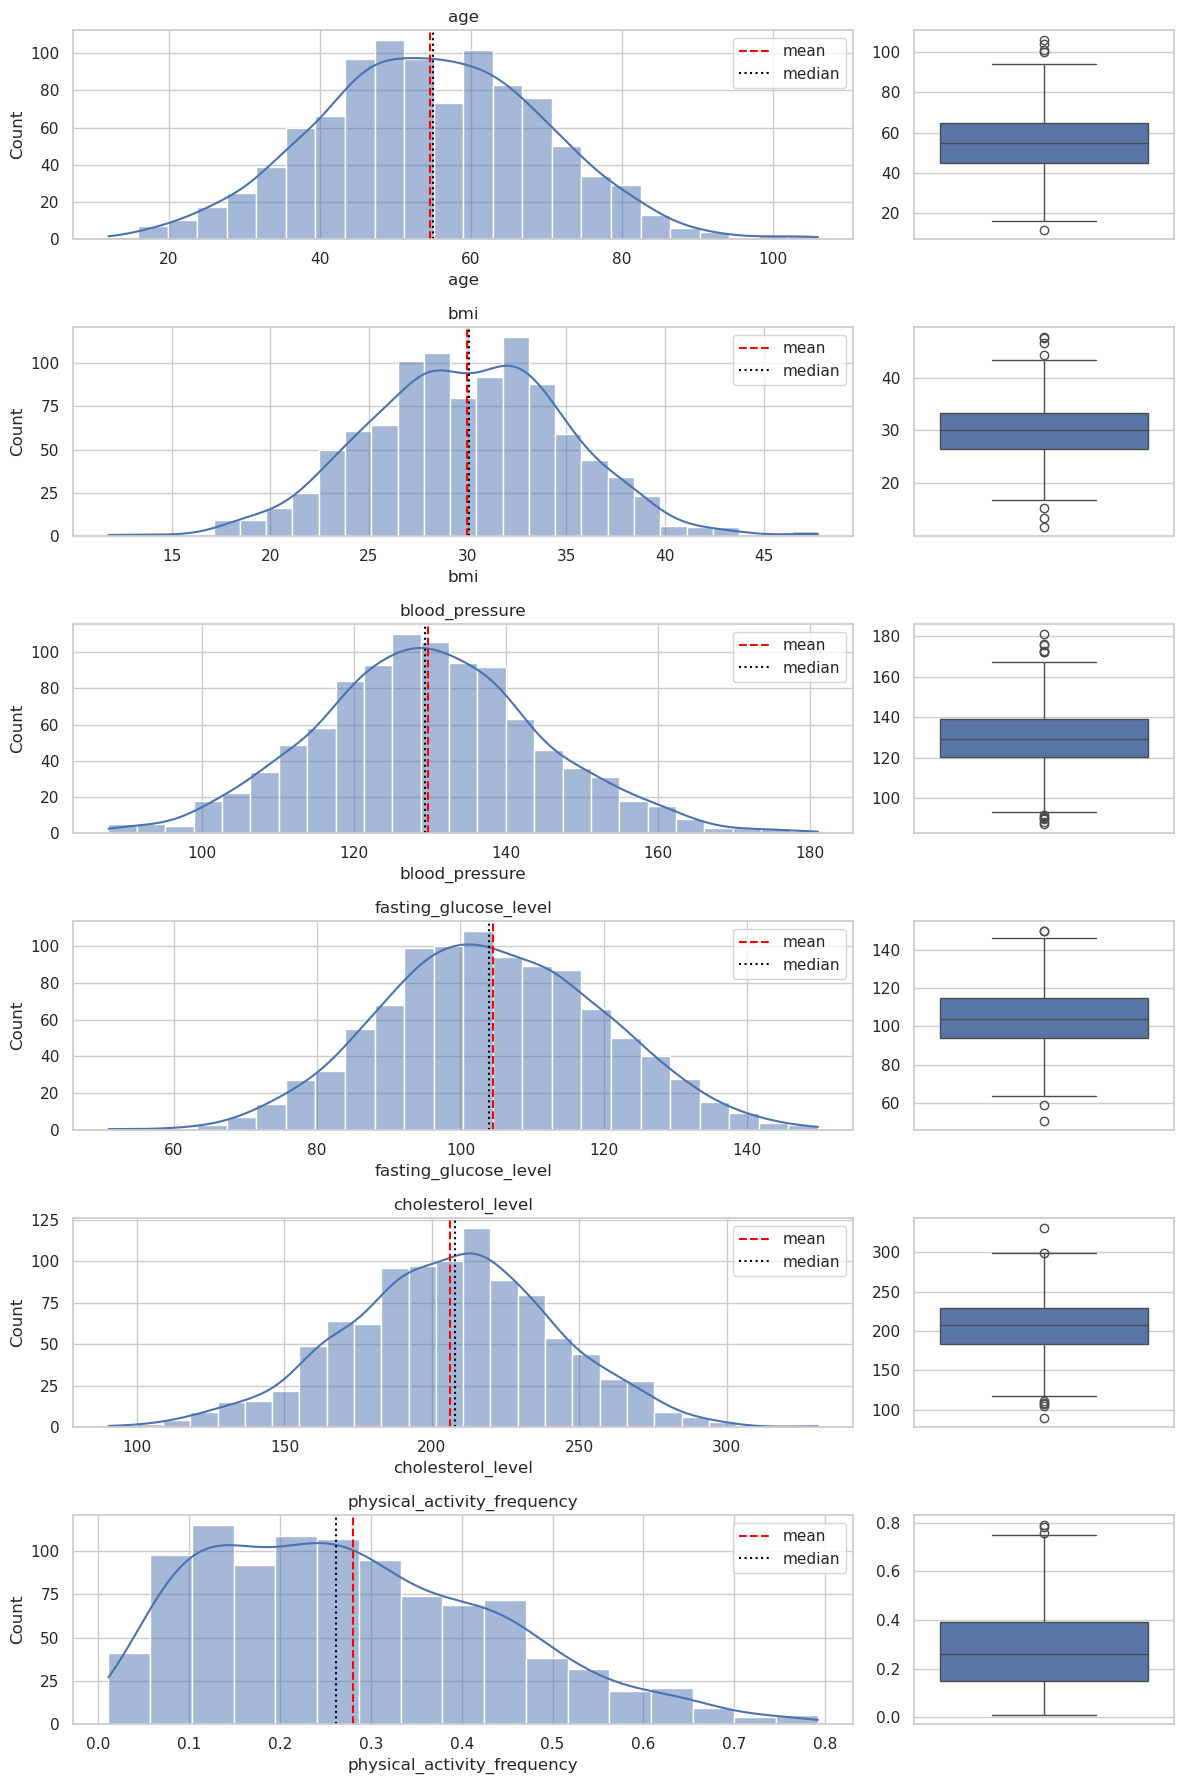

In [32]:
fig, axes = plt.subplots(
    len(NUM_COLS), 2, figsize=(12, 3 * len(NUM_COLS)), gridspec_kw={"width_ratios": [3, 1]}
)
for (ax_hist, ax_box), col in zip(axes, NUM_COLS):
    sns.histplot(df[col], kde=True, ax=ax_hist)
    ax_hist.axvline(df[col].mean(), color="red", ls="--", label="mean")
    ax_hist.axvline(df[col].median(), color="black", ls=":", label="median")
    ax_hist.set_title(col)
    ax_hist.legend()
    sns.boxplot(y=df[col], ax=ax_box)
    ax_box.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "univariate_numeric.png", dpi=120)
plt.show()

### 4.3 Normality

The z-score outlier rule (|z| > 3) assumes the data is roughly normal, so we check that first.
- **Shapiro–Wilk test:** the null hypothesis is that the data is normal, so p < 0.05 means we reject normality. With n = 1000 the test is very sensitive and can reject even tiny, harmless departures, so read it together with the plots.
- **Q–Q plot:** if the data is normal, the points lie on the straight line. Curling at the ends means heavy or light tails, and a bow shape means skew.

In [33]:
normality = pd.DataFrame(
    {c: stats.shapiro(df[c]) for c in NUM_COLS}, index=["W", "p_value"]
).T
normality["normal_at_5pct"] = normality["p_value"] > 0.05
normality.round(4)

,W,p_value,normal_at_5pct
age,0.9982,0.3683,True
bmi,0.9984,0.4634,True
blood_pressure,0.9978,0.2217,True
fasting_glucose_level,0.9987,0.6852,True
cholesterol_level,0.9988,0.7336,True
physical_activity_frequency,0.9650,0.0000,False


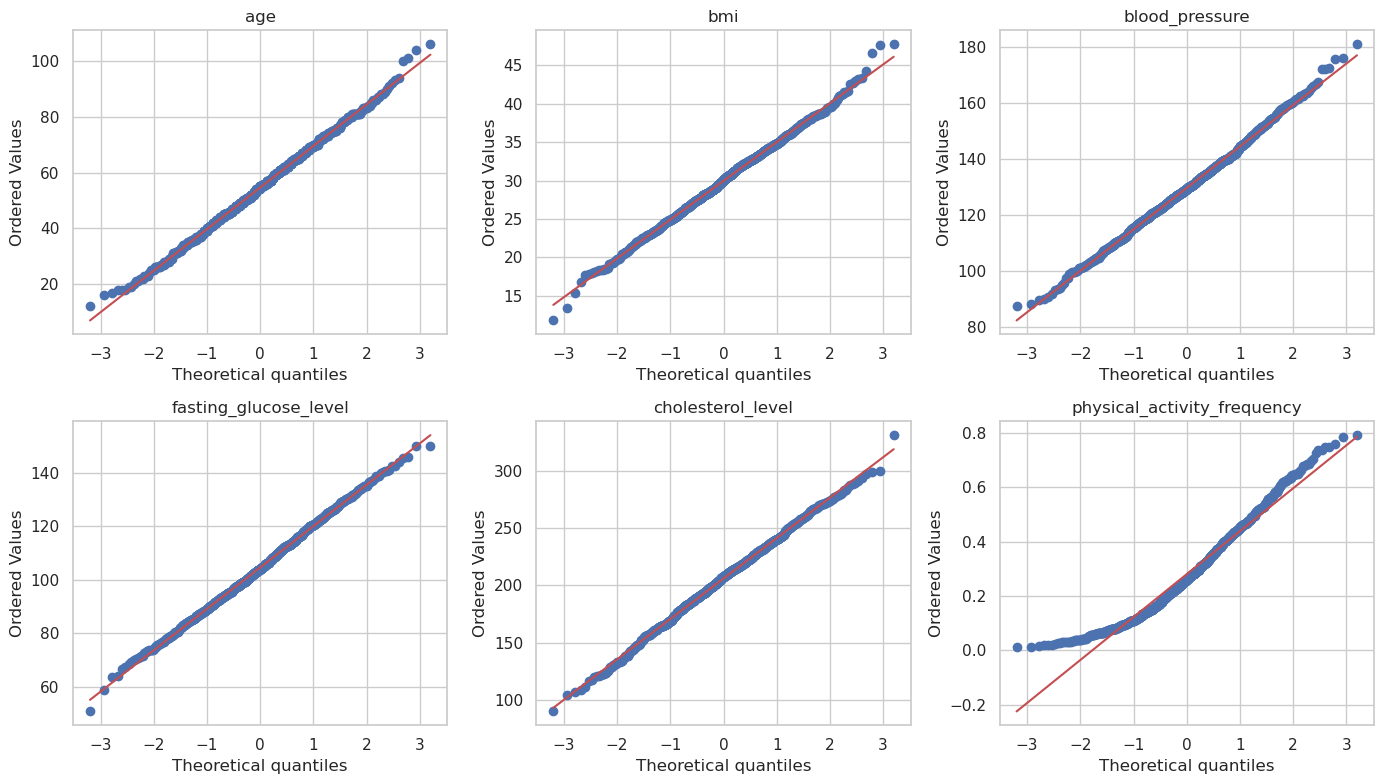

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, NUM_COLS):
    stats.probplot(df[col], dist="norm", plot=ax)
    ax.set_title(col)
fig.tight_layout()
fig.savefig(FIG_DIR / "qq_plots.png", dpi=120)
plt.show()

**Interpretation**

- **age, bmi, blood_pressure, fasting_glucose_level, cholesterol_level** look close to normal. Skew and kurtosis are near 0, mean ≈ median, Shapiro–Wilk p > 0.05 for all five, and the Q–Q points sit on the line. Perfect normality like this is unusual in real clinical data, where glucose and BMI are usually right-skewed, and is a hint that the data is synthetic.
- **physical_activity_frequency** is the exception. It is right-skewed (skew 0.57), bounded at 0, and Shapiro–Wilk rejects normality (p < 0.001). For this column the IQR method is more trustworthy than z-scores, and a transform (e.g. square root) might help linear models.
- Because almost every feature is near-normal, the IQR and z-score methods should mostly agree.

## 5. Outlier analysis

We compare two standard methods:
- **IQR method:** flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. It makes no assumption about the distribution and is robust, because the fences are built from quartiles.
- **Z-score method:** flags values more than 3 standard deviations from the mean. It assumes normality, and the outliers themselves inflate the mean and SD it relies on.

When both methods flag a value, that is stronger evidence it is a genuine outlier.

In [35]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


iqr_flags = pd.DataFrame({c: ~df[c].between(*iqr_bounds(df[c])) for c in NUM_COLS})
z_flags = pd.DataFrame({c: np.abs(stats.zscore(df[c])) > 3 for c in NUM_COLS})

fences = pd.DataFrame(
    {c: iqr_bounds(df[c]) for c in NUM_COLS}, index=["lower_fence", "upper_fence"]
).T
outliers = fences.assign(
    n_iqr=iqr_flags.sum(),
    pct_iqr=iqr_flags.mean().mul(100),
    n_z=z_flags.sum(),
    n_both=(iqr_flags & z_flags).sum(),
)
outliers.round(2)

,lower_fence,upper_fence,n_iqr,pct_iqr,n_z,n_both
age,15.00,95.00,5,0.5,4,4
bmi,16.31,43.60,7,0.7,5,5
blood_pressure,91.72,167.77,12,1.2,3,3
fasting_glucose_level,62.74,146.19,4,0.4,1,1
cholesterol_level,113.89,299.28,7,0.7,2,2
physical_activity_frequency,-0.22,0.76,3,0.3,2,2


In [36]:
any_iqr = iqr_flags.any(axis=1)
both = (iqr_flags & z_flags).any(axis=1)
print("Rows with >=1 IQR outlier:", any_iqr.sum())
print("Rows flagged by both methods:", both.sum())
df[both]

Rows with >=1 IQR outlier: 34
Rows flagged by both methods: 15


,age,bmi,blood_pressure,fasting_glucose_level,cholesterol_level,physical_activity_frequency,family_history_of_diabetes,diabetes_diagnosis
27,100,43.24,137.37,113.34,258.14,0.0753,Absent,Negative
135,101,32.06,141.67,108.06,219.96,0.3130,Absent,Negative
185,37,13.48,107.14,73.45,182.12,0.5260,Present,Positive
194,72,34.34,181.03,123.46,183.24,0.3200,Absent,Negative
209,47,23.38,132.69,88.20,181.56,0.7840,Absent,Negative
433,60,46.65,175.70,134.79,264.95,0.0543,Absent,Negative
456,106,36.95,143.68,107.40,271.62,0.2530,Present,Negative
478,79,35.33,152.46,112.90,330.87,0.0398,Present,Negative
662,39,24.94,130.12,76.78,186.34,0.7920,Present,Positive
732,41,11.80,107.62,50.85,138.36,0.4270,Absent,Positive


Before we decide whether to remove outliers, we check how many of them are positive cases. If extreme values cluster among diabetics, dropping them would throw away exactly the high-risk patients we want to detect.

In [37]:
pd.DataFrame({
    "outlier_rows": df.loc[any_iqr, TARGET].value_counts(normalize=True).mul(100),
    "all_rows": df[TARGET].value_counts(normalize=True).mul(100),
}).round(1)

,outlier_rows,all_rows
diabetes_diagnosis,,
Negative,64.7,85.0
Positive,35.3,15.0


**Interpretation**

- Outliers are rare: 0.3–1.2% per column by IQR, and **34 rows (3.4%)** have at least one. Blood pressure has the most IQR outliers (12), but only 3 pass the stricter z-score rule. Its tails are long, but the values are still realistic (88–181 mmHg).
- **15 rows** are flagged by both methods. These are the strongest candidates for a closer look.
- **Statistical outlier ≠ error.** Most flagged values are clinically possible: a systolic BP of 181, BMI 47.7, cholesterol 331. The ones that look like *errors or out-of-scope patients* are the implausible values from §3.4 (ages 12–17 and 101–106, BMI 11.8).
- **Outliers are over-represented among positives:** 35% of outlier rows are `Positive`, against 15% overall. Removing outliers would disproportionately remove the minority class we're trying to detect.

**Decision for now:** keep all rows. Options to evaluate during preprocessing:
1. Drop only the 7 implausible rows (or only the minors, if the project targets adults).
2. Cap (winsorise) extreme values at the IQR fences instead of dropping them.
3. Leave them as they are and rely on tree-based models, which are robust to outliers. Use scaling such as `RobustScaler` for linear models.

Whichever we choose, apply it to the training split only, so the test set reflects real-world data.

## 6. Univariate analysis: categorical features & target

                            count   pct
family_history_of_diabetes             
Absent                        600  60.0
Present                       400  40.0 

                    count   pct
diabetes_diagnosis             
Negative              850  85.0
Positive              150  15.0 



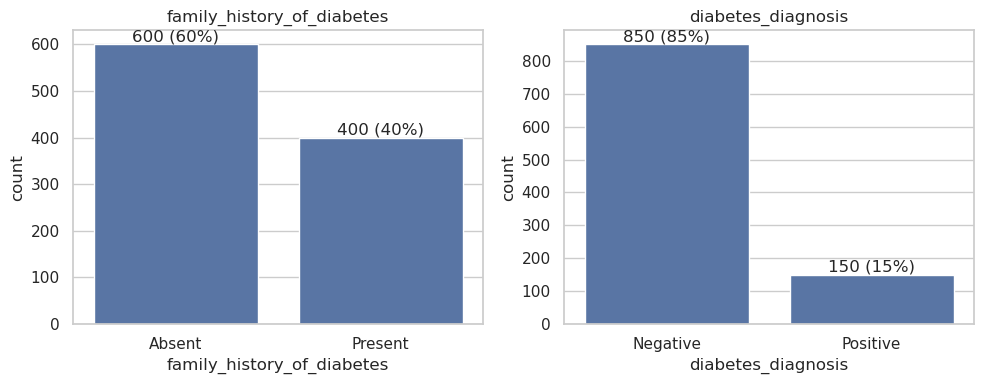

In [38]:
fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(5 * len(CAT_COLS), 4))
for ax, col in zip(axes, CAT_COLS):
    counts = df[col].value_counts()
    pct = df[col].value_counts(normalize=True).mul(100)
    print(pd.DataFrame({"count": counts, "pct": pct.round(1)}), "\n")
    sns.countplot(x=df[col], order=counts.index, ax=ax)
    ax.bar_label(ax.containers[0], labels=[f"{n} ({p:.0f}%)" for n, p in zip(counts, pct)])
    ax.set_title(col)
fig.tight_layout()
fig.savefig(FIG_DIR / "univariate_categorical.png", dpi=120)
plt.show()

**Interpretation**

- **family_history_of_diabetes:** 60% Absent and 40% Present. It's reasonably balanced, so no rare-category issues.
- **diabetes_diagnosis (target):** 850 Negative and 150 Positive, so **15% positive, a moderate class imbalance**. As the literature review found:
  - Accuracy is misleading here, because a model that always predicts `Negative` scores 85%. Use recall, PR-AUC, F2 and calibration instead.
  - Use a **stratified** train/test split and stratified k-fold CV, so every fold keeps about 15% positives.
  - Consider class weights or threshold tuning, and apply any resampling (e.g. SMOTE) inside CV folds only.

## 7. Summary of univariate findings

**Data quality**
- 1000 rows × 8 columns, with no missing values, no blank strings, no duplicates and clean categorical levels. No cleaning is strictly required.
- 7 rows contain values outside adult clinical ranges (ages 12–17 and 101–106, BMI 11.8). They are flagged, not removed.

**Distributions**
- Five of the six numeric features are almost perfectly normal. That is unusual for clinical data and suggests synthetic generation.
- `physical_activity_frequency` is right-skewed and non-normal, so consider a transform.

**Outliers**
- 34 rows (3.4%) have at least one IQR outlier, and 15 are flagged by both IQR and z-score. Most are plausible extreme values, not errors.
- Outlier rows are 35% positive (vs 15% overall), so dropping outliers would cost us positive cases.

**Target**
- 15% positive is an imbalanced binary problem. Plan for stratified splits and imbalance-aware metrics.

**⚠ Red flag to investigate first in bivariate analysis**

A quick look at the class means shows the label goes *against* clinical expectations. Positive cases have **lower** fasting glucose (≈86 vs ≈108 mg/dL), lower BMI, lower blood pressure, are younger and are more active. None of the 86 patients with glucose ≥ 126 mg/dL (the clinical diabetes threshold) is labelled `Positive`. Only family history behaves as expected (24.8% positive with history vs 8.5% without). Possible explanations: the label encoding is inverted, the data was generated without real clinical relationships, or the label means something other than "has diabetes". We should confirm this with proper bivariate plots and, if possible, with whoever provided the data, before modelling.

**Next steps:** bivariate analysis (each feature vs `diabetes_diagnosis`), correlation matrix, then preprocessing decisions (implausible rows, outlier treatment, encoding, scaling).

# Part 2: Bivariate, correlation & target-pattern analysis

Part 1 looked at each column on its own. Part 2 asks **how each feature relates to the target and to the other features**:

8. Bivariate setup
9. Numeric features vs target (distributions, statistical tests, single-feature signal)
10. Categorical feature vs target
11. Correlation analysis (heatmaps, correlation with target, multicollinearity)
12. Pattern identification (positive rate across clinically meaningful bins)
13. Glucose leakage & label-direction assessment
14. Summary of bivariate insights

It also aims to settle the open questions in the README: is fasting glucose leakage (§5.7), is the label direction trustworthy, and which engineered features are worth trying (§5.8)?

## 8. Bivariate setup

- Encode the target as `y` (Positive = 1) so we can correlate it and compute AUCs.
- Encode `family_history_of_diabetes` as 0/1 (Present = 1) so it can join the numeric analyses.
- Record the **clinically expected direction** of each feature (+1 means a higher value should mean higher diabetes risk). This lets us check whether the data behaves the way medicine says it should.

In [39]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score, roc_curve

y = (df[TARGET] == "Positive").astype(int)

df_enc = df[NUM_COLS].copy()
df_enc["family_history"] = (df["family_history_of_diabetes"] == "Present").astype(int)
FEATURES = df_enc.columns.tolist()

CLASS_ORDER = ["Negative", "Positive"]
CLASS_PALETTE = {"Negative": "tab:blue", "Positive": "tab:orange"}

# Clinically expected sign of the relationship with diabetes risk (+1: higher value -> higher risk)
EXPECTED_DIRECTION = pd.Series({
    "age": 1,
    "bmi": 1,
    "blood_pressure": 1,
    "fasting_glucose_level": 1,
    "cholesterol_level": 1,
    "physical_activity_frequency": -1,
    "family_history": 1,
})

print(f"Positive rate: {y.mean():.1%}")

Positive rate: 15.0%


## 9. Numeric features vs target

### 9.1 Class-wise summary

We compare the mean and median of every feature for Negative and Positive cases. The `matches_clinical` column checks whether the difference goes in the direction the literature expects, e.g. Positive cases should have *higher* BMI.

In [40]:
means = df_enc.groupby(df[TARGET]).mean().T
medians = df_enc.groupby(df[TARGET]).median().T

class_summary = pd.DataFrame({
    "mean_negative": means["Negative"],
    "mean_positive": means["Positive"],
    "median_negative": medians["Negative"],
    "median_positive": medians["Positive"],
})
class_summary["diff_pos_minus_neg"] = class_summary["mean_positive"] - class_summary["mean_negative"]
class_summary["expected_direction"] = EXPECTED_DIRECTION
class_summary["matches_clinical"] = (
    np.sign(class_summary["diff_pos_minus_neg"]) == class_summary["expected_direction"]
)
class_summary.round(3)

,mean_negative,mean_positive,median_negative,median_positive,diff_pos_minus_neg,expected_direction,matches_clinical
age,56.334,44.920,56.000,45.000,-11.414,1,False
bmi,30.687,25.843,30.850,25.890,-4.843,1,False
blood_pressure,131.367,120.426,130.840,120.550,-10.941,1,False
fasting_glucose_level,107.860,85.967,107.015,86.500,-21.894,1,False
cholesterol_level,207.918,195.476,209.410,192.550,-12.442,1,False
physical_activity_frequency,0.263,0.380,0.240,0.382,0.118,-1,False
family_history,0.354,0.660,0.000,1.000,0.306,1,True


### 9.2 Distributions by class

KDE curves are drawn with `common_norm=False`, so **each class is normalised separately**. Otherwise the Positive curve (only 150 rows) would look tiny next to the Negative curve (850 rows), and we couldn't compare their shapes. The more the two curves overlap, the less a feature separates the classes.

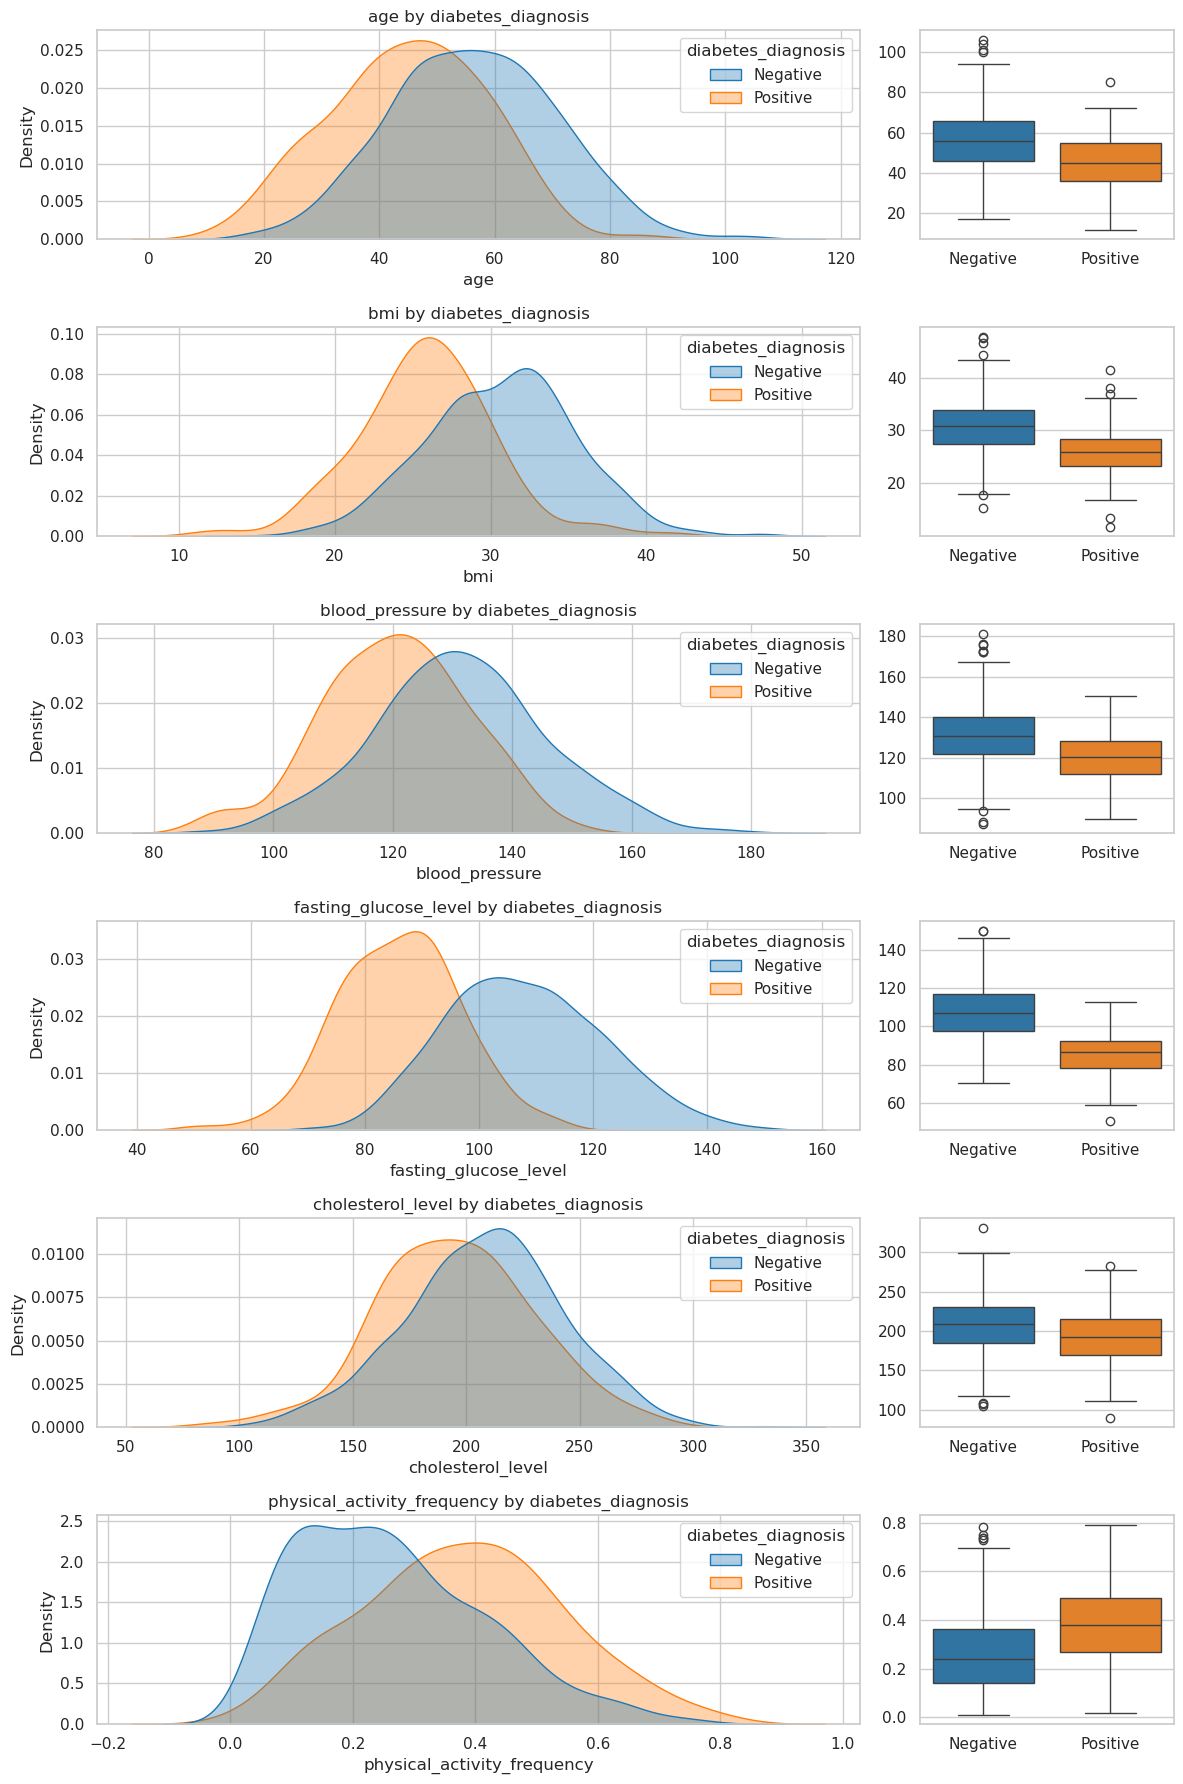

In [41]:
fig, axes = plt.subplots(
    len(NUM_COLS), 2, figsize=(12, 3 * len(NUM_COLS)), gridspec_kw={"width_ratios": [3, 1]}
)
for (ax_kde, ax_box), col in zip(axes, NUM_COLS):
    sns.kdeplot(
        data=df, x=col, hue=TARGET, hue_order=CLASS_ORDER, palette=CLASS_PALETTE,
        common_norm=False, fill=True, alpha=0.35, ax=ax_kde,
    )
    ax_kde.set_title(f"{col} by {TARGET}")
    sns.boxplot(
        data=df, x=TARGET, y=col, hue=TARGET, order=CLASS_ORDER, hue_order=CLASS_ORDER,
        palette=CLASS_PALETTE, legend=False, ax=ax_box,
    )
    ax_box.set_xlabel("")
    ax_box.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "bivariate_numeric_vs_target.png", dpi=120)
plt.show()

### 9.3 Statistical tests, effect sizes and single-feature signal

- **Mann–Whitney U test:** are the two classes' distributions different? It is non-parametric, so it doesn't assume normality (which matters for `physical_activity_frequency`). With n = 1000, even small differences become "significant", so we also look at **effect sizes**:
  - **Cohen's d:** the difference in means, in pooled standard deviations (≈0.2 small, 0.5 medium, 0.8 large).
  - **Rank-biserial r:** the non-parametric equivalent, from −1 to 1.
- **Single-feature ROC-AUC:** how well the feature *alone* ranks Positives above Negatives. 0.5 is random and 1.0 is perfect. `auc_alone` takes whichever direction works better, so it measures signal strength regardless of sign. `higher_value_means` shows which class that direction points to.

In [42]:
rows = {}
for col in NUM_COLS:
    pos, neg = df.loc[y == 1, col], df.loc[y == 0, col]
    u, p = stats.mannwhitneyu(pos, neg, alternative="two-sided")
    pooled_sd = np.sqrt(
        ((len(pos) - 1) * pos.var() + (len(neg) - 1) * neg.var()) / (len(pos) + len(neg) - 2)
    )
    rows[col] = {
        "mann_whitney_p": p,
        "cohens_d": (pos.mean() - neg.mean()) / pooled_sd,
        "rank_biserial_r": 2 * u / (len(pos) * len(neg)) - 1,
    }
tests = pd.DataFrame(rows).T

auc = pd.Series({c: roc_auc_score(y, df_enc[c]) for c in FEATURES})
signal = pd.DataFrame({
    "auc_alone": np.maximum(auc, 1 - auc),
    "higher_value_means": np.where(auc >= 0.5, "more Positive", "more Negative"),
})

(
    tests.join(signal, how="right")
    .sort_values("auc_alone", ascending=False)
    .round({"cohens_d": 3, "rank_biserial_r": 3, "auc_alone": 3})
)

,mann_whitney_p,cohens_d,rank_biserial_r,auc_alone,higher_value_means
fasting_glucose_level,5.142148e-55,-1.647,-0.799,0.900,more Negative
bmi,9.522116e-28,-1.022,-0.559,0.779,more Negative
blood_pressure,2.587325e-17,-0.767,-0.433,0.716,more Negative
age,8.836550e-17,-0.798,-0.426,0.713,more Negative
physical_activity_frequency,8.111155e-16,0.759,0.412,0.706,more Positive
family_history,NaN,NaN,NaN,0.653,more Positive
cholesterol_level,3.417742e-05,-0.357,-0.212,0.606,more Negative


**Interpretation**

- **Every numeric feature differs significantly between the classes** (all Mann–Whitney p < 1e-4). Effect sizes vary a lot:
  - **large:** fasting glucose (d = −1.65) and BMI (d = −1.02)
  - **medium:** age (−0.80), blood pressure (−0.77) and physical activity (+0.76)
  - **small:** cholesterol (−0.36)
- **Signal on its own (single-feature AUC):** glucose **0.90** ≫ BMI 0.78 > blood pressure 0.72 ≈ age 0.71 ≈ activity 0.71 > family history 0.65 > cholesterol 0.61. Every feature carries real signal, and glucose dominates.
- **⚠ Direction:** all six numeric features go **against** clinical expectation (`matches_clinical = False`). Positive cases are *younger*, *leaner*, have *lower* blood pressure, glucose and cholesterol, and are *more* active. The KDE plots show the shift clearly, especially for glucose (Positive median ≈ 87 vs Negative ≈ 107 mg/dL). Section 13 examines this.

## 10. Categorical feature vs target

For `family_history_of_diabetes` we use:
- a **crosstab** with the % Positive in each group,
- a **chi-square test of independence**: is the diagnosis independent of family history?
- the **odds ratio** with a 95% confidence interval: how many times higher the odds of being Positive are with a family history. If the CI excludes 1, the association is significant.

In [43]:
ct = pd.crosstab(df["family_history_of_diabetes"], df[TARGET])
chi2, p, dof, _ = stats.chi2_contingency(ct)

a, b = ct.loc["Present", "Positive"], ct.loc["Present", "Negative"]
c, d = ct.loc["Absent", "Positive"], ct.loc["Absent", "Negative"]
odds_ratio = (a * d) / (b * c)
se_log_or = np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
ci_low, ci_high = np.exp(np.log(odds_ratio) + np.array([-1.96, 1.96]) * se_log_or)

print(f"Chi-square = {chi2:.1f} (dof = {dof}), p = {p:.1e}")
print(f"Odds ratio (Present vs Absent) = {odds_ratio:.2f}, 95% CI {ci_low:.2f}-{ci_high:.2f}")

ct["pct_positive"] = (ct["Positive"] / ct.sum(axis=1) * 100).round(1)
ct

Chi-square = 48.4 (dof = 1), p = 3.4e-12
Odds ratio (Present vs Absent) = 3.54, 95% CI 2.46-5.10


diabetes_diagnosis,Negative,Positive,pct_positive
family_history_of_diabetes,,,
Absent,549,51,8.5
Present,301,99,24.8


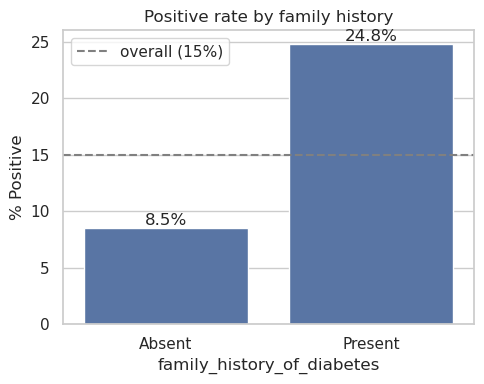

In [44]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=ct.index, y=ct["pct_positive"], ax=ax)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.axhline(y.mean() * 100, ls="--", color="grey", label=f"overall ({y.mean():.0%})")
ax.set_ylabel("% Positive")
ax.set_title("Positive rate by family history")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "bivariate_family_history.png", dpi=120)
plt.show()

**Interpretation**

- With a family history, **24.8%** are Positive; without one, **8.5%**.
- The association is highly significant (χ² = 48.4, p ≈ 3e-12). The **odds ratio is 3.54 (95% CI 2.46–5.10)**: a family history multiplies the odds of being Positive by about 3.5.
- This is the **only feature that behaves as clinical knowledge expects**. Keep it as a binary (0/1) feature.

## 11. Correlation analysis

### 11.1 Correlation heatmaps

- **Pearson** measures *linear* association. Between a numeric feature and a 0/1 target it is the **point-biserial correlation**.
- **Spearman** measures *monotonic* association using ranks. It is robust to outliers and skew.

If the two agree, the relationships are roughly linear. We include the encoded target (`diabetes_positive`) as the last row and show only the lower triangle, since the matrix is symmetric.

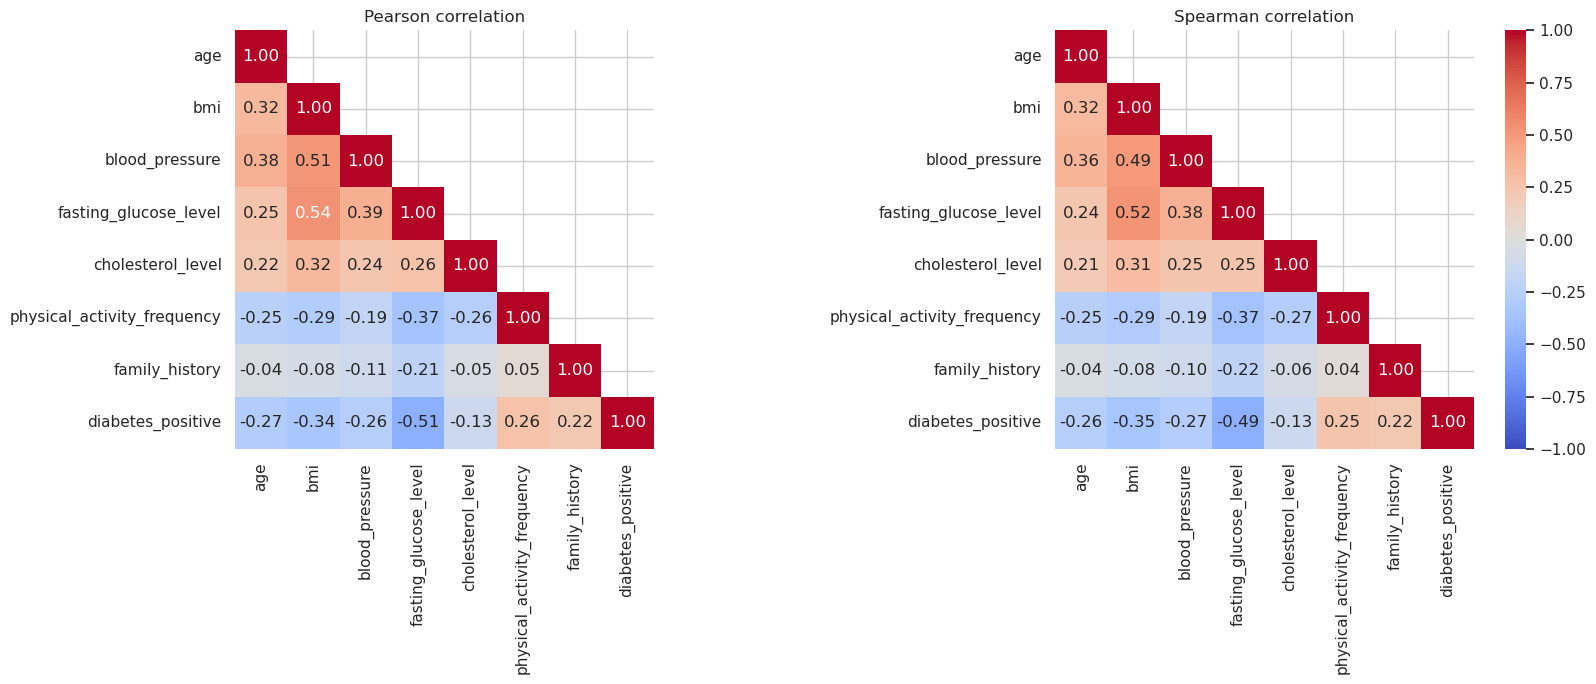

In [45]:
corr_df = df_enc.assign(diabetes_positive=y)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = corr_df.corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(
        corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
        square=True, cbar=ax is axes[-1], ax=ax,
    )
    ax.set_title(f"{method.title()} correlation")
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_heatmaps.png", dpi=120)
plt.show()

### 11.2 Correlation with the target

Features ranked by the strength of their correlation with `diabetes_positive`. A positive bar means a higher value goes with more Positive cases.

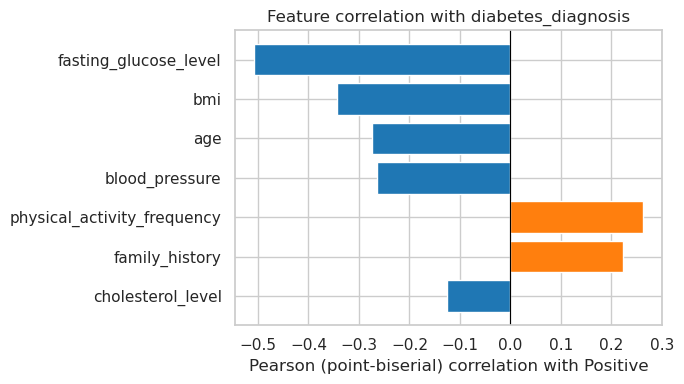

,pearson,spearman
fasting_glucose_level,-0.507,-0.494
bmi,-0.343,-0.345
age,-0.274,-0.263
blood_pressure,-0.264,-0.268
physical_activity_frequency,0.262,0.255
family_history,0.223,0.223
cholesterol_level,-0.126,-0.131


In [46]:
target_corr = pd.DataFrame({
    "pearson": corr_df.corr()["diabetes_positive"].drop("diabetes_positive"),
    "spearman": corr_df.corr("spearman")["diabetes_positive"].drop("diabetes_positive"),
}).sort_values("pearson", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
colors = np.where(target_corr["pearson"] > 0, "tab:orange", "tab:blue")
ax.barh(target_corr.index[::-1], target_corr["pearson"][::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson (point-biserial) correlation with Positive")
ax.set_title("Feature correlation with diabetes_diagnosis")
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation_with_target.png", dpi=120)
plt.show()

target_corr.round(3)

### 11.3 Multicollinearity

When two features are strongly correlated with each other, they carry overlapping information. That makes logistic-regression coefficients unstable and hard to interpret, although tree models are largely unaffected. We check this two ways:
- feature pairs with **|r| > 0.7**,
- the **Variance Inflation Factor**, VIF = 1 / (1 − R²), where R² comes from regressing each feature on all the others. VIF > 5 is a common warning level and VIF > 10 is serious.

In [47]:
feat_corr = df_enc.corr()
pairs = (
    feat_corr.where(np.triu(np.ones_like(feat_corr, dtype=bool), k=1))
    .stack()
    .dropna()
    .rename("r")
)
print("Feature pairs with |r| > 0.7:", (pairs.abs() > 0.7).sum())
print("\nStrongest feature-feature correlations:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(2).to_string())


def vif(X):
    return pd.Series(
        {c: 1 / (1 - LinearRegression().fit(X.drop(columns=c), X[c]).score(X.drop(columns=c), X[c]))
         for c in X.columns},
        name="VIF",
    )


vif(df_enc).sort_values(ascending=False).round(2)

Feature pairs with |r| > 0.7: 0

Strongest feature-feature correlations:
bmi                    fasting_glucose_level          0.54
                       blood_pressure                 0.51
blood_pressure         fasting_glucose_level          0.39
age                    blood_pressure                 0.38
fasting_glucose_level  physical_activity_frequency   -0.37


bmi                            1.75
fasting_glucose_level          1.61
blood_pressure                 1.50
age                            1.24
physical_activity_frequency    1.23
cholesterol_level              1.18
family_history                 1.05
Name: VIF, dtype: float64

### 11.4 Pairplot

Scatter plots of every pair of numeric features, coloured by class. Look for regions where Positives (orange) cluster, i.e. combinations of features that separate the classes better than any one feature does.

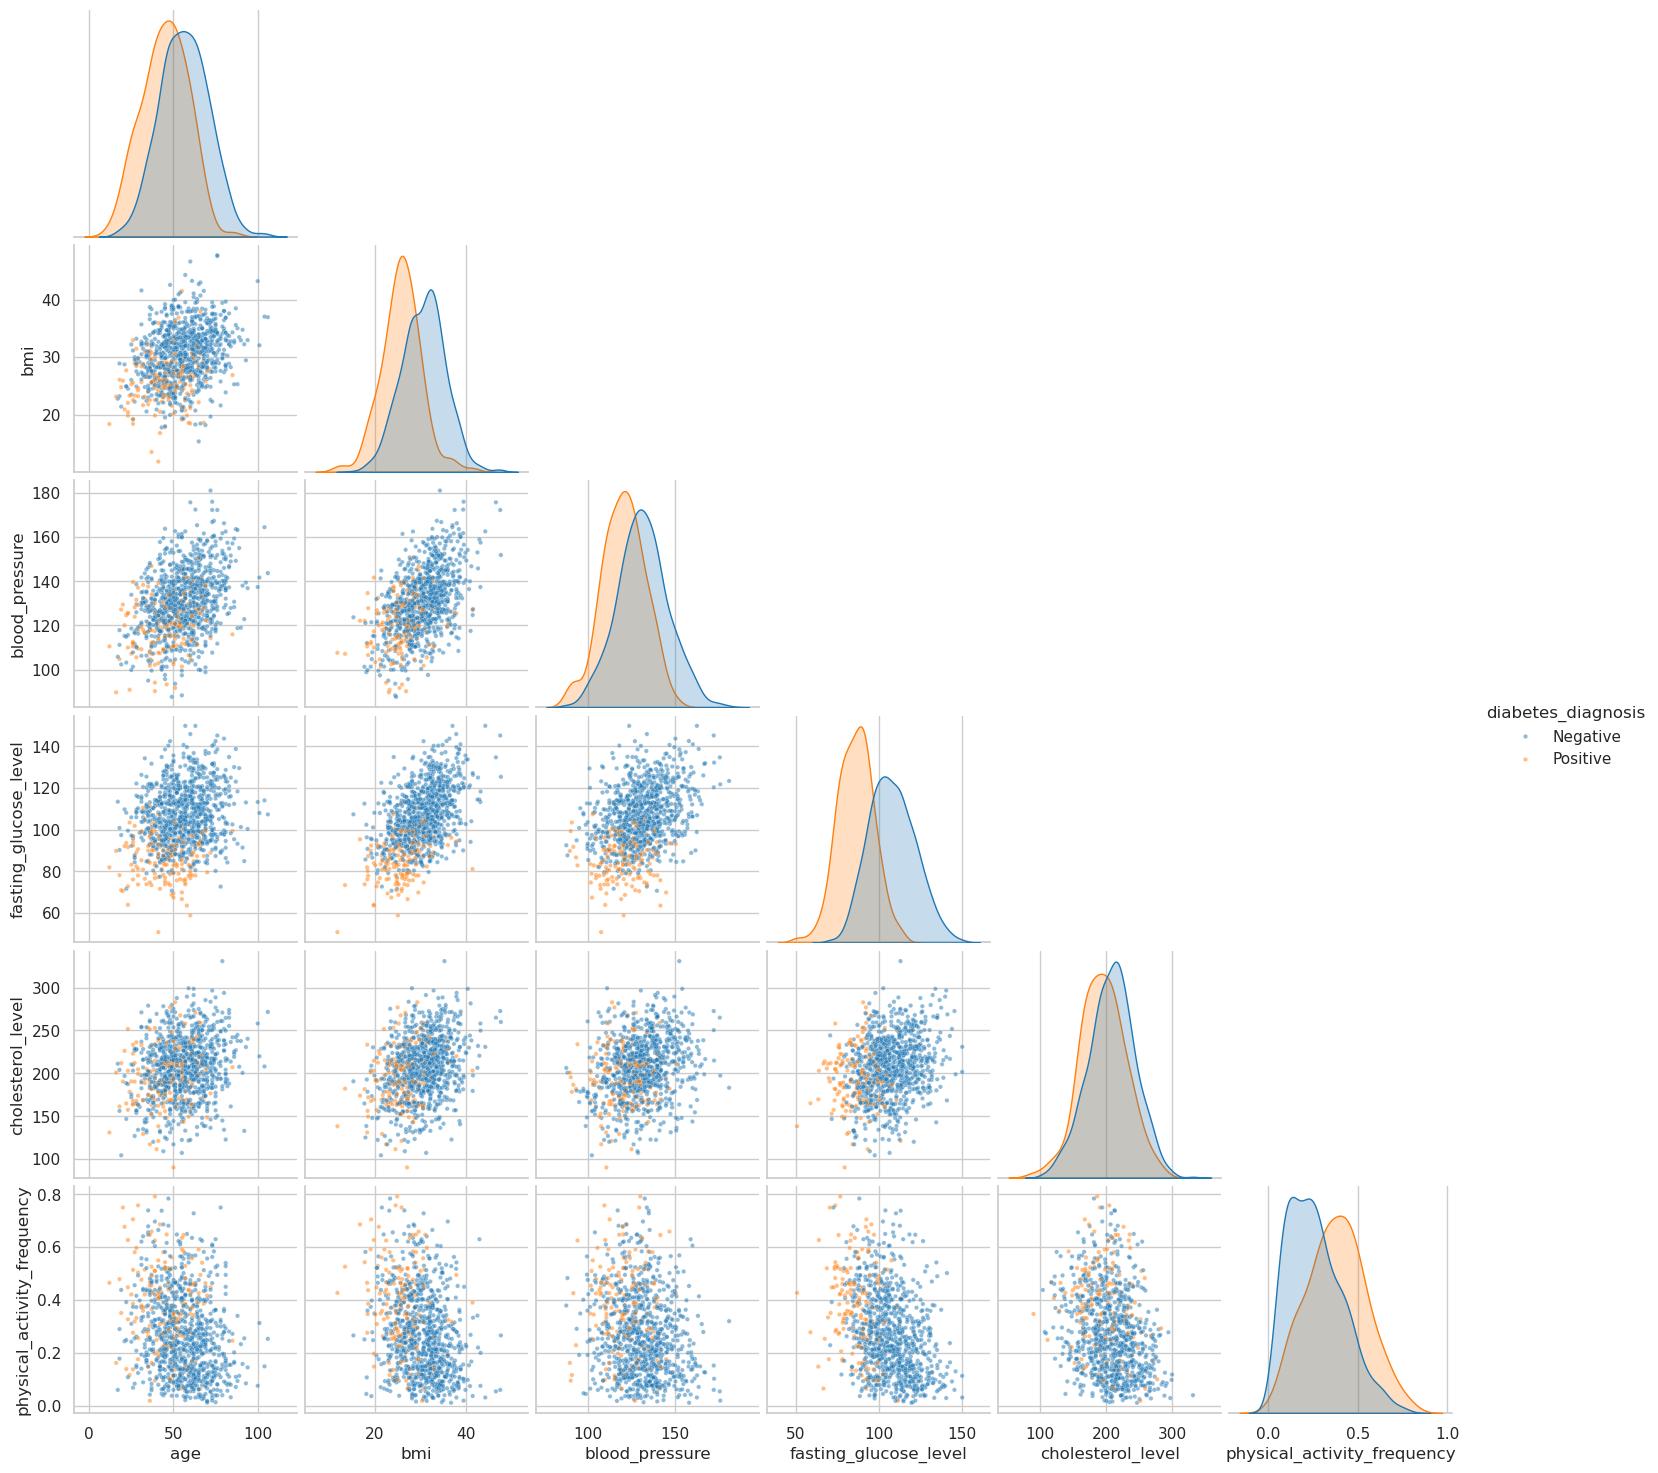

In [48]:
g = sns.pairplot(
    df, vars=NUM_COLS, hue=TARGET, hue_order=CLASS_ORDER, palette=CLASS_PALETTE,
    corner=True, diag_kind="kde", diag_kws={"common_norm": False},
    plot_kws={"s": 10, "alpha": 0.5},
)
g.figure.savefig(FIG_DIR / "pairplot_by_target.png", dpi=100)
plt.show()

**Interpretation**

- **Pearson ≈ Spearman** for every pair (differences ≤ 0.02). The relationships are monotonic and roughly linear, so logistic regression should capture them well, without transforms or splines.
- **Correlation with the target:** glucose −0.51 is the strongest. BMI (−0.34), age (−0.27), blood pressure (−0.26), activity (+0.26) and family history (+0.22) are moderate, and cholesterol (−0.13) is weak.
- **No multicollinearity problem:** no feature pair has |r| > 0.7, and every VIF is below 2 (max 1.75 for BMI). We can keep all features, and logistic-regression coefficients will be stable.
- **A useful clue:** the *feature–feature* correlations are clinically sensible. BMI rises with glucose (0.54) and blood pressure (0.51), age with blood pressure (0.38), and activity falls as glucose rises (−0.37). The features are internally consistent; **only their relationship with the label is reversed**. That points to the label, not the features, as the source of the anomaly.
- **Pairplot:** Positives cluster in the low-glucose / low-BMI / low-BP corner of the scatter plots.

## 12. Pattern identification: positive rate across clinical bins

We group each feature into **clinically meaningful bins** and compute the % Positive in each. This shows the *shape* of each relationship (linear, threshold, U-shaped) in units clinicians understand. It also tests the binned features proposed in README §5.8.

| Feature | Bins (source) |
|---|---|
| fasting_glucose_level | < 100 normal, 100–125 prediabetes, ≥ 126 diabetes (ADA) |
| bmi | < 18.5, 18.5–24.9, 25–29.9, ≥ 30 (WHO) |
| age | < 35, 35–44, 45–64, ≥ 65 (ADA screens from 35) |
| blood_pressure | < 120, 120–129, 130–139, ≥ 140 (AHA systolic categories) |
| physical_activity_frequency | quartiles (no clinical standard for this scale) |

In [49]:
BINS = {
    "fasting_glucose_level": ([0, 100, 126, np.inf], ["<100 normal", "100-125 prediabetes", ">=126 diabetes"]),
    "bmi": ([0, 18.5, 25, 30, np.inf], ["<18.5 under", "18.5-24.9 normal", "25-29.9 over", ">=30 obese"]),
    "age": ([0, 35, 45, 65, np.inf], ["<35", "35-44", "45-64", ">=65"]),
    "blood_pressure": ([0, 120, 130, 140, np.inf], ["<120 normal", "120-129 elevated", "130-139 stage 1", ">=140 stage 2"]),
}

binned = {
    col: pd.cut(df[col], bins=edges, labels=labels, right=False)
    for col, (edges, labels) in BINS.items()
}
binned["physical_activity_frequency"] = pd.qcut(
    df["physical_activity_frequency"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"]
)


def positive_rate(groups):
    table = y.groupby(groups, observed=True).agg(n="size", n_positive="sum", pct_positive="mean")
    table["pct_positive"] = (table["pct_positive"] * 100).round(1)
    return table


for col, groups in binned.items():
    print(f"--- {col}")
    print(positive_rate(groups).to_string(), "\n")

--- fasting_glucose_level
                         n  n_positive  pct_positive
fasting_glucose_level                               
<100 normal            402         137          34.1
100-125 prediabetes    512          13           2.5
>=126 diabetes          86           0           0.0 

--- bmi
                    n  n_positive  pct_positive
bmi                                            
<18.5 under        13           7          53.8
18.5-24.9 normal  154          53          34.4
25-29.9 over      330          70          21.2
>=30 obese        503          20           4.0 

--- age
         n  n_positive  pct_positive
age                                 
<35     86          32          37.2
35-44  162          39          24.1
45-64  490          69          14.1
>=65   262          10           3.8 

--- blood_pressure
                    n  n_positive  pct_positive
blood_pressure                                 
<120 normal       245          70          28.6
120-129 elevat

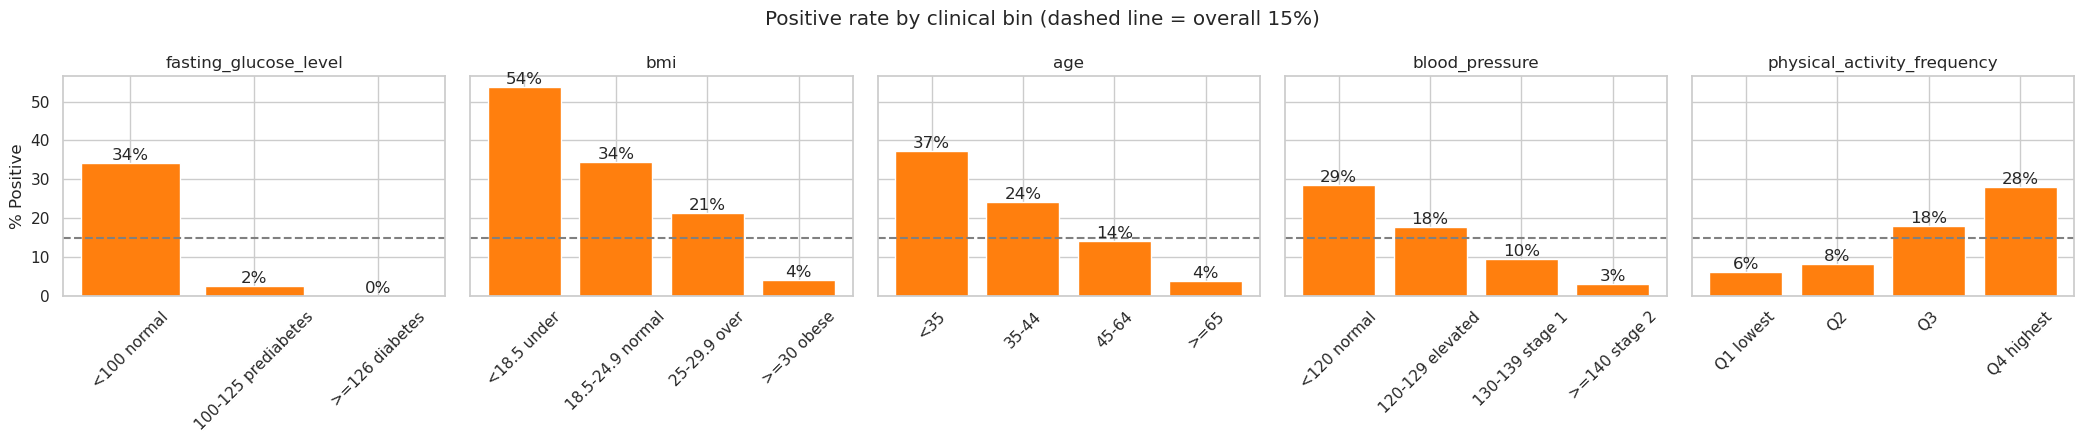

In [50]:
fig, axes = plt.subplots(1, len(binned), figsize=(4.2 * len(binned), 4.5), sharey=True)
for ax, (col, groups) in zip(axes, binned.items()):
    rates = positive_rate(groups)
    ax.bar(rates.index.astype(str), rates["pct_positive"], color="tab:orange")
    ax.bar_label(ax.containers[0], fmt="%.0f%%")
    ax.axhline(y.mean() * 100, ls="--", color="grey")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("% Positive")
fig.suptitle("Positive rate by clinical bin (dashed line = overall 15%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "positive_rate_by_bin.png", dpi=120)
plt.show()

### 12.1 Interaction: family history × BMI category

Does family history change the effect of BMI? If the gap between the two rows differs across columns, that points to an interaction worth modelling.

In [51]:
pd.crosstab(
    binned["bmi"], df["family_history_of_diabetes"], values=y, aggfunc="mean"
).mul(100).round(1)

family_history_of_diabetes,Absent,Present
bmi,,
<18.5 under,50.0,57.1
18.5-24.9 normal,22.6,48.6
25-29.9 over,14.3,31.3
>=30 obese,0.3,10.1


### 12.2 Clinical risk-factor count

Scores like FINDRISC add up risk factors. Clinically, the positive rate should **rise** as more risk factors are present. We count six simple ones: age ≥ 45, BMI ≥ 30, BP ≥ 130, glucose ≥ 100, below-median activity, and family history.

In [52]:
risk_factors = pd.DataFrame({
    "age_45_plus": df["age"] >= 45,
    "bmi_30_plus": df["bmi"] >= 30,
    "bp_130_plus": df["blood_pressure"] >= 130,
    "glucose_100_plus": df["fasting_glucose_level"] >= 100,
    "low_activity": df["physical_activity_frequency"] < df["physical_activity_frequency"].median(),
    "family_history": df["family_history_of_diabetes"] == "Present",
})
positive_rate(risk_factors.sum(axis=1).rename("n_risk_factors"))

,n,n_positive,pct_positive
n_risk_factors,,,
0,30,15,50.0
1,109,45,41.3
2,201,49,24.4
3,211,31,14.7
4,209,8,3.8
5,183,2,1.1
6,57,0,0.0


**Interpretation**

- **Every binned feature shows a steep, monotonic gradient, in the reversed direction:**
  - glucose: < 100 → **34%** Positive, prediabetes → 2.5%, ≥ 126 → **0%**
  - BMI: underweight → **54%**, obese → **4%**
  - age: < 35 → **37%**, ≥ 65 → **4%**
  - blood pressure: normal → **29%**, stage 2 → **3%**
  - activity: lowest quartile → **6%**, highest quartile → **28%**
- **The relationships are monotonic, with no thresholds or U-shapes.** Binning therefore adds little predictive value over the raw continuous features: trees find their own splits, and LR handles monotonic trends. Clinical bins are mainly useful for **interpretability** (explaining risk to clinicians), not performance.
- **Family history × BMI:** family history raises the positive rate in every BMI band (e.g. normal BMI 22.6% → 48.6%, obese 0.3% → 10.1%). The relative effect looks larger at high BMI, but those cells are small. An `fh × bmi` interaction term is worth **trying** in LR, but it isn't a priority.
- **The risk-factor count is perfectly inverted.** Clinically, more risk factors should mean more diabetes. Here the positive rate *falls* from **50%** (0 risk factors) to **0%** (all 6). A FINDRISC-style score would rank patients backwards on this data.

## 13. Glucose leakage & label-direction assessment

README §5.7 set a rule: if glucose relates to the label *too closely* (near-deterministically), treat it as **leakage** and exclude it. Here we collect the evidence:
1. Positive rate across finer glucose bands.
2. The best single glucose cut-off: how well does one threshold on glucose alone classify?
3. A direction check: for every feature, does the observed relationship match the clinical expectation?

In [53]:
glucose_bands = pd.cut(df["fasting_glucose_level"], [0, 70, 80, 90, 100, 110, 126, np.inf], right=False)
positive_rate(glucose_bands)

,n,n_positive,pct_positive
fasting_glucose_level,,,
"[0.0, 70.0)",9,9,100.0
"[70.0, 80.0)",44,36,81.8
"[80.0, 90.0)",119,50,42.0
"[90.0, 100.0)",230,42,18.3
"[100.0, 110.0)",232,10,4.3
"[110.0, 126.0)",280,3,1.1
"[126.0, inf)",86,0,0.0


In [54]:
# The best single threshold on glucose (Youden's J = sensitivity + specificity - 1).
# Lower glucose -> Positive in this data, so we score with -glucose.
fpr, tpr, thresholds = roc_curve(y, -df["fasting_glucose_level"])
best = np.argmax(tpr - fpr)
cutoff = -thresholds[best]
print(f"Glucose alone, ROC-AUC = {roc_auc_score(y, -df['fasting_glucose_level']):.3f}")
print(f"Rule 'Positive if glucose <= {cutoff:.1f} mg/dL': "
      f"sensitivity = {tpr[best]:.2f}, specificity = {1 - fpr[best]:.2f}")

Glucose alone, ROC-AUC = 0.900
Rule 'Positive if glucose <= 94.1 mg/dL': sensitivity = 0.81, specificity = 0.85


In [55]:
direction_check = pd.DataFrame({
    "expected": EXPECTED_DIRECTION.map({1: "higher -> more risk", -1: "higher -> less risk"}),
    "corr_with_positive": target_corr["pearson"].round(3),
    "auc_alone": signal["auc_alone"].round(3),
})
direction_check["matches_clinical"] = np.sign(direction_check["corr_with_positive"]) == EXPECTED_DIRECTION.reindex(direction_check.index)
direction_check.sort_values("auc_alone", ascending=False)

,expected,corr_with_positive,auc_alone,matches_clinical
fasting_glucose_level,higher -> more risk,-0.507,0.900,False
bmi,higher -> more risk,-0.343,0.779,False
blood_pressure,higher -> more risk,-0.264,0.716,False
age,higher -> more risk,-0.274,0.713,False
physical_activity_frequency,higher -> less risk,0.262,0.706,False
family_history,higher -> more risk,0.223,0.653,True
cholesterol_level,higher -> more risk,-0.126,0.606,False


**Interpretation**

**1. Is fasting glucose leakage?**
- Glucose is by far the strongest single predictor: AUC 0.90, and one cut-off (Positive if glucose ≤ 94 mg/dL) gives sensitivity 0.81 and specificity 0.85.
- It is **not deterministic**, though. The classes overlap, with 42 Positives at 90–100 mg/dL and 13 in the prediabetes range.
- Classic leakage would mean the label was *derived from* the ADA diagnostic rule (glucose ≥ 126 → diabetes). If so, all 86 rows with glucose ≥ 126 would be Positive. **None of them are.** So the label is clearly **not** a re-encoding of the glucose diagnostic threshold.
- **Verdict:** glucose is a *dominant* feature, but under the README §5.7 rule it is **not near-deterministic leakage**. We still train models **with and without** glucose, to measure how much the other features can achieve alone, which is what early detection needs.

**2. Is the label direction trustworthy?**
6 of 7 features relate to the label in the *opposite* direction to clinical knowledge, while the features are consistent with each other. Possible explanations:

| Hypothesis | Consistent with the data? | Implication |
|---|---|---|
| **A. Labels swapped** (Positive ↔ Negative) | Partly. It would fix the 6 numeric features, but then family history would become *protective* and prevalence would be **85%**, which is implausible for a screening population | Not a clean explanation, so don't flip the labels |
| **B. Synthetic generator with non-clinical rules** | Yes. The filename says synthetic, the distributions are near-perfectly normal, and the gradients are smooth and monotonic | The model can learn the pattern, but clinical priors and the literature's expected directions don't transfer |
| **C. The label means something else** (e.g. a different condition or a "low-risk" flag) | Possibly. Positives look young, lean and active | The project framing would need to change |

**Decision:** model the label **as given**. Report the anomaly clearly as a limitation (TRIPOD+AI asks for the outcome definition to be stated), and **raise it with the data provider or instructor** before drawing any clinical conclusions. Don't invert or "fix" the labels without confirmation.

## 14. Summary of bivariate insights

**Key drivers** (ranked by single-feature AUC):

| Rank | Feature | AUC alone | Corr. with Positive | Effect size | Matches clinical? |
|---|---|---|---|---|---|
| 1 | fasting_glucose_level | 0.90 | −0.51 | d = −1.65 (large) | ✗ |
| 2 | bmi | 0.78 | −0.34 | d = −1.02 (large) | ✗ |
| 3 | blood_pressure | 0.72 | −0.26 | d = −0.77 (medium) | ✗ |
| 4 | age | 0.71 | −0.27 | d = −0.80 (medium) | ✗ |
| 5 | physical_activity_frequency | 0.71 | +0.26 | d = +0.76 (medium) | ✗ |
| 6 | family_history | 0.65 | +0.22 | OR = 3.54 | ✓ |
| 7 | cholesterol_level | 0.61 | −0.13 | d = −0.36 (small) | ✗ |

**Correlation & multicollinearity:** relationships are monotonic and close to linear (Pearson ≈ Spearman). No pair has |r| > 0.7 and every VIF < 2, so **all 7 features can be kept**.

**Glucose:** dominant but not deterministic, and the label wasn't derived from the ≥ 126 rule, so it is **not classic leakage**. We still compare models with and without glucose.

**Label direction:** 6 of 7 features run opposite to clinical expectations. This is most likely a synthetic-data artefact. We **model the label as given**, report it as a limitation, and raise it with the data provider.

**Feature-engineering decisions** (updates README §5.8):

| Candidate | Decision | Reason |
|---|---|---|
| Raw continuous features | **Keep** | Monotonic, near-linear, low VIF |
| `family_history` → 0/1 | **Keep** | Strong, clinically consistent (OR 3.5) |
| sqrt(`physical_activity_frequency`) | **Try** (LR only) | Right-skewed; trees don't need it |
| `family_history × bmi` interaction | **Try** (LR only) | The family-history effect varies across BMI bands, but cells are small |
| Clinical bins (BMI / BP / age / glucose bands) | **Interpretability only** | Monotonic trends mean little predictive gain over raw values |
| Risk-factor count (FINDRISC-style) | **Drop** | Perfectly inverted on this data; it would mislead clinically |

**Implications for modelling**
- The signal is strong (several features have AUC > 0.7), so even the LR baseline should do well. Check that more complex models really add value (README #1).
- Train with and without glucose, and report both.
- Use stratified CV and threshold tuning for recall, as planned.

**Open questions:** confirm the label definition and encoding with the data provider, and decide how to handle the 7 implausible-age/BMI rows (from Part 1).

# Part 3: Data preparation

Parts 1–2 told us *what* the data looks like. Part 3 turns those findings into a **model-ready dataset**, one step at a time, with the reason for each choice:

15. Data cleaning
16. Feature engineering
17. Data splitting
18. Feature encoding
19. Feature scaling
20. Full preprocessor (feature sets with and without glucose)
21. Summary and config draft for the `src/` pipeline

**The golden rule: nothing learned from data may see the test set.**
- Steps that use only the values in one row (dropping a row by a fixed rule, `sqrt(x)`, `a × b`) are safe **before** the split.
- Steps that *learn statistics* (a scaler's mean and SD, an encoder's categories) are fitted **after** the split, on the training data only, and later inside each CV fold through a `Pipeline`.

## 15. Data cleaning

From Part 1, the data has no missing values, blank strings or duplicates, so the only cleaning decision is about the **implausible values** (§3.4):

| Rows | Decision | Reason |
|---|---|---|
| age < 18 (12, 16, 17) | **Drop** | Outside the adult screening population this project targets |
| age > 100 (101, 104, 106) | Keep | Rare but possible; still adults in scope |
| BMI 11.8 | Keep | Extreme but a single row; dropping it would also lose a Positive |
| Statistical outliers (§5) | Keep | 35% are Positive, so removing them would cost minority-class cases |

`MIN_AGE` is a fixed rule that needs no statistics from the data, so applying it before the split is leak-free. We re-check the Part 1 guarantees with `assert`, so the notebook stops loudly if the data ever changes.

In [ ]:
MIN_AGE = 18  # adult screening population

assert df.isna().sum().sum() == 0, "unexpected missing values"
assert not df.duplicated().any(), "unexpected duplicate rows"

minors = df["age"] < MIN_AGE
print(f"Dropping {minors.sum()} row(s) with age < {MIN_AGE}")
df_clean = df.loc[~minors].reset_index(drop=True)

print(f"Rows: {len(df)} -> {len(df_clean)}")
print(f"Positives: {(df[TARGET] == 'Positive').sum()} -> {(df_clean[TARGET] == 'Positive').sum()} "
      f"({(df_clean[TARGET] == 'Positive').mean():.1%})")
df.loc[minors]

## 16. Feature engineering

From the decisions in §14:

| Feature | Formula | Used by | Why |
|---|---|---|---|
| `sqrt_physical_activity` | √`physical_activity_frequency` | Logistic Regression | Reduces the right skew (0.57). Linear models fit better on a symmetric feature |
| `family_history_x_bmi` | family history (0/1) × `bmi` | Logistic Regression | Lets the BMI effect differ with family history (§12.1). Trees find interactions on their own |

Both use only values from the same row, so they're computed **before** the split. The clinical bins from §12 (`BINS`) are kept for interpretability only and are **not** model features: the relationships are monotonic, so bins would only throw information away.

In [ ]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    """Adds row-wise engineered features (safe to compute before the train/test split)."""
    out = data.copy()
    out["sqrt_physical_activity"] = np.sqrt(out["physical_activity_frequency"])
    out["family_history_x_bmi"] = (out["family_history_of_diabetes"] == "Present").astype(int) * out["bmi"]
    return out


df_fe = engineer_features(df_clean)
ENGINEERED_FEATURES = ["sqrt_physical_activity", "family_history_x_bmi"]

pd.DataFrame({
    "skew": df_fe[["physical_activity_frequency", "sqrt_physical_activity"]].skew(),
    "shapiro_p": [stats.shapiro(df_fe[c]).pvalue for c in ["physical_activity_frequency", "sqrt_physical_activity"]],
}).round(4)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["physical_activity_frequency", "sqrt_physical_activity"]):
    sns.histplot(df_fe[col], kde=True, ax=ax)
    ax.set_title(f"{col} (skew {df_fe[col].skew():.2f})")
fig.tight_layout()
fig.savefig(FIG_DIR / "sqrt_activity_transform.png", dpi=120)
plt.show()

**Interpretation**

- The square root removes the skew: **0.57 → −0.06**, and the histogram becomes roughly symmetric. Shapiro–Wilk still rejects normality (p < 0.001), because the variable is bounded and has a flat top, but symmetry is what matters for a linear model.
- Both engineered features are now in `df_fe`. We judge whether they are *useful* only after the split, on training data (§17.1).

## 17. Data splitting

- A **stratified 80/20 train/test split** (`stratify=y`) keeps the ~15% positive share in both sets. Without stratification, a random split could give the small test set noticeably more or fewer positives.
- **No separate validation set.** With only 148 positives, a 10% validation split would hold about 15, too few for stable metrics. Instead, model selection and threshold tuning use **stratified 5-fold CV on the training set** (README §5.4).
- The **test set is set aside now** and used once, for the final evaluation.
- `random_state=42` makes the split reproducible.

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split

TEST_SIZE = 0.2
RANDOM_STATE = 42
CV_FOLDS = 5

X_all = df_fe.drop(columns=[TARGET])
y_all = (df_fe[TARGET] == "Positive").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_STATE,
)

pd.DataFrame(
    {
        "rows": [len(y_all), len(y_train), len(y_test)],
        "positives": [y_all.sum(), y_train.sum(), y_test.sum()],
        "pct_positive": [y_all.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
    },
    index=["all", "train", "test"],
).round(1)

Each CV fold should also keep the class ratio. Below are the positives per validation fold from `StratifiedKFold` on the training set:

In [ ]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
pd.DataFrame(
    [
        {"fold": i, "val_rows": len(val_idx), "val_positives": int(y_train.iloc[val_idx].sum()),
         "val_pct_positive": round(y_train.iloc[val_idx].mean() * 100, 1)}
        for i, (_, val_idx) in enumerate(cv.split(X_train, y_train), start=1)
    ]
).set_index("fold")

### 17.1 Checking the engineered features (training set only)

Now that the split exists, we judge the engineered features **on the training data only**, so these choices don't peek at the test set.

Note: **monotonic transforms like √x don't change the AUC or how a tree splits**, because they keep the order of the values. They only help models that assume linear relationships, which is why `sqrt_physical_activity` is meant for Logistic Regression only.

In [ ]:
check_cols = ["physical_activity_frequency", "sqrt_physical_activity", "bmi", "family_history_x_bmi"]
pd.DataFrame({
    "corr_with_positive": [X_train[c].corr(y_train) for c in check_cols],
    "auc_alone": [max(roc_auc_score(y_train, X_train[c]), 1 - roc_auc_score(y_train, X_train[c])) for c in check_cols],
}, index=check_cols).round(3)

**Interpretation** (training set only)

- `sqrt_physical_activity` has **the same AUC as the raw feature (0.704)**, as expected for a monotonic transform. Its correlation barely moves (0.254 → 0.247). Its benefit, if any, is a more linear fit in Logistic Regression, and CV will show whether that matters.
- `family_history_x_bmi` is **weak on its own** (AUC 0.59, weaker than family history alone at 0.65). That's because the BMI part points in the opposite direction to family history. Its value can only appear *alongside* the main effects in LR.
- **Decision:** keep both as *candidates* for the LR variant, and **drop them if stratified CV shows no gain** over the plain LR baseline.

## 18. Feature encoding

Models need numbers, so text categories must be encoded.

| Column | Values | Encoder | Result |
|---|---|---|---|
| `family_history_of_diabetes` | Absent / Present | `OneHotEncoder(drop="if_binary")` | One 0/1 column, `family_history_of_diabetes_Present` |
| `diabetes_diagnosis` (target) | Negative / Positive | Mapped by hand in §17 | `y`: Positive = 1 |

Why these choices:
- **One-hot** fits *nominal* categories, which have no natural order. For a two-level column, `drop="if_binary"` keeps only one column, because the second would be perfectly redundant (Absent = 1 − Present).
- The encoder lives **inside the preprocessor**, so the final pipeline accepts the raw strings `Absent`/`Present` exactly as they appear in the CSV.
- An unseen category (e.g. `"Unknown"`) raises an error, because `handle_unknown="error"` is the default. That is a deliberate data-quality guard.
- *If* clinical bins were ever used as features, they would be **ordinal** (underweight < normal < overweight < obese) and would need an `OrdinalEncoder` with an explicit category order.

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

BINARY_FEATURES = ["family_history_of_diabetes"]

encoder = OneHotEncoder(drop="if_binary", sparse_output=False).fit(X_train[BINARY_FEATURES])
print("Learned categories:", encoder.categories_)
print("Output column(s):", list(encoder.get_feature_names_out()))

sample = X_train[BINARY_FEATURES].head(6)
sample.assign(encoded=encoder.transform(sample).ravel().astype(int))

## 19. Feature scaling

`StandardScaler` rescales every numeric feature to mean 0 and SD 1: z = (x − mean) / SD.

- **Why scale?** Logistic Regression with regularisation penalises coefficients, and that penalty is only fair if all features are on the same scale. Otherwise cholesterol (SD ≈ 35) and activity (SD ≈ 0.16) would be penalised very differently. Tree models split on thresholds, so scaling doesn't change them, but it does no harm either.
- **Why `StandardScaler` and not `RobustScaler`?** The features are close to normal, and outliers are few (≤ 1.2% per column, §5). `RobustScaler` (median/IQR) helps when heavy outliers distort the mean and SD, which isn't the case here.
- **Fitted on the training set only.** The mean and SD are learned from `X_train` and then *applied* to `X_test`. So the training set ends up with exactly mean 0 and SD 1, while the test set is only *close* to that. That difference is the sign that no test information leaked into the scaler.

In [ ]:
scale_cols = NUM_COLS + ENGINEERED_FEATURES
scaler = StandardScaler().fit(X_train[scale_cols])

train_scaled = pd.DataFrame(scaler.transform(X_train[scale_cols]), columns=scale_cols)
test_scaled = pd.DataFrame(scaler.transform(X_test[scale_cols]), columns=scale_cols)

pd.DataFrame({
    "learned_mean": scaler.mean_,
    "learned_sd": scaler.scale_,
    "train_mean": train_scaled.mean(),
    "train_sd": train_scaled.std(ddof=0),
    "test_mean": test_scaled.mean(),
    "test_sd": test_scaled.std(ddof=0),
}, index=scale_cols).round(3)

## 20. Full preprocessor

We combine scaling and encoding into one `ColumnTransformer`. Any column not listed is dropped (`remainder="drop"`), so only the chosen features reach the model.

**Feature sets** (README §5.7: train with and without glucose):

| Set | Numeric features |
|---|---|
| `with_glucose` | all 6 raw numeric features |
| `without_glucose` | the same, minus `fasting_glucose_level`: only non-laboratory features, closer to real early screening |

**Model variants:**
- **Trees** (Decision Tree, RF, GBM) use the raw numeric features.
- **Logistic Regression** swaps `physical_activity_frequency` for `sqrt_physical_activity` and adds `family_history_x_bmi`. Keeping both the raw and sqrt versions would just duplicate information.

In [ ]:
from sklearn.compose import ColumnTransformer


def build_preprocessor(numeric_features, binary_features=BINARY_FEATURES) -> ColumnTransformer:
    """Scales numeric features and one-hot encodes binary ones; every other column is dropped."""
    return ColumnTransformer(
        [
            ("num", StandardScaler(), numeric_features),
            ("bin", OneHotEncoder(drop="if_binary"), binary_features),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def lr_numeric(numeric_features):
    """LR variant: sqrt activity instead of raw, plus the family-history x BMI interaction."""
    swapped = ["sqrt_physical_activity" if c == "physical_activity_frequency" else c for c in numeric_features]
    return swapped + ["family_history_x_bmi"]


FEATURE_SETS = {
    "with_glucose": NUM_COLS,
    "without_glucose": [c for c in NUM_COLS if c != "fasting_glucose_level"],
}

rows = {}
for set_name, numeric in FEATURE_SETS.items():
    for variant, cols in {"trees": numeric, "logistic_regression": lr_numeric(numeric)}.items():
        preprocessor = build_preprocessor(cols).fit(X_train)
        Xt_train, Xt_test = preprocessor.transform(X_train), preprocessor.transform(X_test)
        rows[(set_name, variant)] = {
            "n_features": Xt_train.shape[1],
            "train_shape": Xt_train.shape,
            "test_shape": Xt_test.shape,
            "any_nan": bool(np.isnan(Xt_train).any() or np.isnan(Xt_test).any()),
            "features": ", ".join(preprocessor.get_feature_names_out()),
        }

pd.DataFrame(rows).T

### 20.1 Leakage-safe pattern for modelling

In the modelling stage the preprocessor goes **inside a `Pipeline`** together with the model. Then `cross_validate` / `GridSearchCV` **refit the scaler on each training fold**, so the validation fold never influences the scaling. Fitting the scaler once on all of `X_train` before CV would leak a little information from every validation fold.

Imbalance is handled with `class_weight="balanced"`, not resampling (README §5.2). The cell below only *builds* the pipeline; training happens in the modelling stage.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

example_pipeline = Pipeline([
    ("preprocessor", build_preprocessor(lr_numeric(FEATURE_SETS["with_glucose"]))),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
example_pipeline

## 21. Summary and config draft for the `src/` pipeline

| Step | Decision | Where it runs | Evidence |
|---|---|---|---|
| Cleaning | Drop **3 rows with age < 18** (2 Positive, 1 Negative). Keep ages > 100, BMI 11.8 and all statistical outliers | Before the split (fixed rule) | §3.4, §5 |
| Result | **997 rows, 148 Positive (14.8%)** | | §15 |
| Feature engineering | `sqrt_physical_activity` (skew 0.57 → −0.06) and `family_history_x_bmi` for **LR only**; kept only if CV shows a gain. Clinical bins for interpretability only | Before the split (row-wise) | §14, §16, §17.1 |
| Splitting | **Stratified 80/20**, `random_state=42` → train 797 (118 Positive) / test 200 (30 Positive). No separate validation set; **stratified 5-fold CV** on train (23–24 positives per fold) | | §17 |
| Encoding | `family_history_of_diabetes` → `OneHotEncoder(drop="if_binary")`, one 0/1 column. Target: Positive = 1 | Inside the pipeline | §18 |
| Scaling | `StandardScaler` on numeric features, **fitted on training data / each CV fold only** | Inside the pipeline | §19 |
| Feature sets | `with_glucose` (7 features for trees, 8 for LR) and `without_glucose` (6 / 7) | Inside the pipeline | §20 |
| Imbalance | No resampling; `class_weight="balanced"` + threshold tuning (modelling stage) | Model | README §5.2 |

**Draft `src/config.yaml` block** (to port later):

```yaml
file_path: "./data/synthetic_data_166.csv"
target_column: "diabetes_diagnosis"
positive_class: "Positive"
min_age: 18                      # drop rows below this age (EDA §15)
test_size: 0.2                   # stratified train/test split (EDA §17)
random_state: 42
cv: 5                            # stratified k-fold on the training set
numeric_features:
  - age
  - bmi
  - blood_pressure
  - fasting_glucose_level
  - cholesterol_level
  - physical_activity_frequency
binary_features:
  - family_history_of_diabetes
lr_engineered_features:          # LR only; keep if CV shows a gain (EDA §17.1)
  - sqrt_physical_activity
  - family_history_x_bmi
exclude_glucose_variant: true    # also train every model without fasting_glucose_level (README §5.7)
```

**Next:** port `MIN_AGE` cleaning, `engineer_features`, the stratified split and `build_preprocessor` into `src/data_preparation.py` (Mod6 layout), then start modelling with the LR baseline.